# Butadiene Rotation Scan

:::{div}
:class: colab-badge
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/blinkletter/UsingPsi4v2/blob/main/ch4/4C-butadiene/butadiene.ipynb)
:::

When we **optimized** butadiene using a **perfectly flat** $C_{2v}$ structure, we obtained an optimized structure with a central **dihedral angle** of 0°. Yet any other structure where we start with a dihedral angle of near, but not exactly, 0° finds a **lower energy** conformation to have a **dihedral angle** of 35.4°. That geometry has an energy that is XXX kJ/mole **lower than** the perfect **perfectly flat** $C_{2v}$ structure.

Perhaps we should **check every angle** between 0° and 180° and **look for** any other surprises. 

## Setting up this Notebook

The collapsed [code cell below](#setup-cell-butadiene) will **load in** all the *Python* packages and set global variables for the calculations in this notebook. If you are using *Colab*, **run this cell first**, watch it eventually crash, and then **run it again** and you will be set up.

In [10]:
#| label: setup-cell-butadiene
#| tags: [remove-output, hide-input]

####################################################
### Import Libraries and set up global variables ###
####################################################

from pathlib import Path
import json

import sys

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# Install packages only if needed
# Google Colab does not include every Python package
#
# Psi4 cannot be installed with pip. On Colab we first install conda
# (condacolab), which RESTARTS the session. After the restart, run
# this cell again and Psi4 will be installed with conda.
try:                  # if the package exists import it, otherwise install it
    import psi4
except ImportError:
    if IN_COLAB:
        !pip -q install condacolab
        import condacolab
        condacolab.install()
        !mamba install -q -y -c conda-forge psi4
    import psi4

try:
    import py3Dmol
except ImportError:
    !pip -q install py3Dmol
    import py3Dmol

try:
    import skimage          # scikit-image draws the static orbital and density surfaces
except ImportError:
    !pip -q install scikit-image
    import skimage

# Standard imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Style sheets and helper functions from the book's GitHub repository
if IN_COLAB and not Path("styles/tufte.mplstyle").exists():
    !wget -q -P styles https://raw.githubusercontent.com/blinkletter/UsingPsi4v2/main/styles/tufte.mplstyle
    !wget -q -P styles https://raw.githubusercontent.com/blinkletter/UsingPsi4v2/main/styles/S2_classic2.mplstyle
    !wget -q -N https://raw.githubusercontent.com/blinkletter/UsingPsi4v2/main/psi4_helpers.py

# The methane structure file used in this chapter
if IN_COLAB and not Path("data/methane.xyz").exists():
    !wget -q -P data https://raw.githubusercontent.com/blinkletter/UsingPsi4v2/main/ch3/3A-methane/data/methane.xyz

if IN_COLAB:
    plt.style.use("styles/tufte.mplstyle")
else:
    sys.path.insert(0, "../..")                 # psi4_helpers.py is two folders up
    plt.style.use("../../styles/tufte.mplstyle")

import psi4_helpers as ph

# Psi4 output (.out, .log, .molden, cube files, scans) goes into output/, which is not kept in git.
# Small results files that another page reads (.json, .csv) go into data/, which is kept in git.
output_dir = Path("output")
output_dir.mkdir(parents=True, exist_ok=True)
data_dir = Path("data")
data_dir.mkdir(parents=True, exist_ok=True)

# 3D pictures: False = static images (as in the book); True = rotatable py3Dmol viewers
INTERACTIVE = True

### Setting *Psi4* Options

The [code below](#setup-function-butadiene) sets **options** for the *Psi4* package. I set the number of threads to 2, which is the limit for *Google Colab*. Your own computer may have more processor cores, but *Colab* will **only allow** you the power of two for free.

there is also a **function** named `zmat_variables()` that will take the **molecule** object, get the text for the Z-matrix that describes the optimized structure and **extract** the values of all named **variables**. We will use this later to read the results.

In [11]:
#| label: setup-function-butadiene
#| tags: [remove-output]

# a function to collect the zmatrix variables into a dictionary using the text zmatrix in the mol object.
def zmat_variables(mol):
    """Return the Z-matrix variables of mol as a {name: value} dictionary."""
    text = mol.create_psi4_string_from_molecule()
    variables = text.split("\n\n", 1)[1]     # the variable are separated by a blank line. We will split the text block here and use the second part (position [1])
    zvars = {}
    for line in variables.strip().splitlines():
        name, value = line.split("=")
        zvars[name.strip()] = float(value)
    return zvars


# Resources for every calculation on this page (house limits: 4 GB, 4 threads)
psi4.set_memory("4 GB")
psi4.set_num_threads(4)

# Exact (non-density-fitted) integrals
psi4.set_options({"scf_type": "pk"})

# style for plots in this notebook
plt.style.use("../../styles/tufte.mplstyle")


## A Better Z-matrix

In the [previous notebook](simple_butadiene.ipynb#conformers-of-butadiene-simple), we used a Z-matrix that described the structure of **butadiene** and set a **variable** for the **central bond** torsion. Below, we will construct a similat Z-matrix, but we will use variables to describe all bond lengths, angles and dihedrals. This way we can **query** any structural **parameter** by calling for the value if a **variable** using the `mol.get_variable()` function that is built into the **molecule object**. The **variable** for the dihedral angle of the **central bond** is still set as `D` and we will use it as before.

In [25]:
#| label: butadiene-zmatrix-perfect

zmat = '''
0 1
C
C   1  rCCterm
C   2  rCCcent      1  aCCC
C   3  rCCterm      2  aCCC         1  D
H   1  rCHtermen    2  aHCCendo     3  tHCCCendo
H   1  rCHtermex    5  aHCHterm     2  tHCHC
H   2  rCHcent      1  aHCCcent     3  tHCCCcent
H   3  rCHcent      4  aHCCcent     2  tHCCCcent
H   4  rCHtermen    3  aHCCendo     2  tHCCCendo
H   4  rCHtermex    9  aHCHterm     3  tHCHC

rCCcent = 1.5
rCCterm = 1.4
rCHtermen = 1.1
rCHtermex = 1.1
rCHcent = 1.1
aCCC = 120
aHCCendo = 120
aHCHterm = 120
aHCCcent = 120
tHCCCendo  =   0.0
tHCHC  = 180.0
tHCCCcent = 180.0
D   = 180
'''

mol = psi4.geometry(zmat)

### The Power of Symmetry

You will observe that **many variables** that describe the bond **lengths**, **angles** and **dihedrals** are used **more than once**. This is because of **symmetry**. The molecule has $C2$ symmetry and this can be expressed using variables. The C{sub}`1`–C{sub}`2` bond is **identical** to the C{sub}`3`–C{sub}`4` bond and both are described by the **same** variable for **distance**, `rCCterm`. *Psi4* will change the value of the **variable** during the optimization and, because the **same** variable applies to those two **identical** bonds, an equivalent bond distance is enforced. The same is true for the pair of bond angles labeled `aHCHterm` and the pair of angles labeled `aHCCendo`. 

Because of the $C_2$ **symmetry**, every parameter is **paired** except for the central C{sub}`2`–C{sub}`3` bond. It has a **unique** bond distance, `rCCcent`, and the **unique** dihedral angle, `D`. 

:::{figure} images/symmetrybutadienehighlights.png
:label: fig-butadiene-sym-highlight
:width: 50%
:align: center
:alt: butadiene with labeled distances and angles

Example equivalent parameters in the $C_2$ symmetry of butadiene.
:::

The [code below](#butadiene-relaxed-scan1) will optimize this **symmetrical** structure usinf $C_2$ **symmetry**. We have almost **half** the structural space to optimize using this two-fold **symmetry**. This may **speed** the calculation by making for **less work**. On my own personal computer, the 36 optimizations tool about 90 seconds at the `HF/6-31G` level of theory and about 6 minutes at the `B3LYP-D3BJ/6-31G*` level.



In [26]:
#| label: butadiene-relaxed-scan1
#| tags: [remove-output]
#| class: scroll-input

# Choose a level of theory
theory = "B3LYP-D3BJ/6-31G*"
# theory = "HF/6-31G"

# Freeze the C4-C3-C2-C1 torsion at its starting value in every optimization below
psi4.set_options({"frozen_dihedral": "4 3 2 1"})

results = [] # create empty list for results at each value of 'D'

# set up list of torsion angles to scan through
start, end = 0.0, 180.0             # scan from start to end
n = 5.0                             # with values spaced by this number    
angles = np.arange(start, end+n, n) # make a list from start to end spaced by n

# perform the scan of structures at different torsion angles for central bond
for D in angles:
    psi4.set_output_file(output_dir / f"butadiene_{D:03.0f}.out", False) # filenames will be "butadiene_00X.out"
    mol.set_variable("D", D) # set the torsion angle in the zmatrix of the mol object

    # optimize and return energy and a wavefunction object
    E, wfn = psi4.optimize(theory, molecule = mol, return_wfn = True) 
 
    # get results. We will put them in a list; one set of results for each calculation.
    steps = psi4.variable("OPTIMIZATION ITERATIONS") # record how many steps were taken to reach teh optimized structure
    
    # extract orbital energies from wfn
    eps = wfn.epsilon_a_subset("AO", "ALL").np  # get list of all orbital energies without grouping them by symmetry
    homo = eps[wfn.nalpha() - 1]                # wfn.nalpha() returns number of 'alpha' electrons. Will be same a number of filled orbitals. had to subtract 1 because python started the list from position zero. So position 14 is the 15th MO.
    lumo = eps[wfn.nalpha()]

    # collect symmetry
    point_group = mol.get_full_point_group()
    sym = mol.schoenflies_symbol()   # get symmetry point group used by calculation
    
    # get zmatrix text string from resulting mol object
    z = mol.create_psi4_string_from_molecule()
    xyz = mol.save_string_xyz_file()

    # extract structural information from the z-matrix
    variables = zmat_variables(mol)  # returns a dictionary of all zmat variables

    # add to `results` list to create data object with all the results
    results.append({
        "D": D,
        "E": E,
        "steps": steps,
        "E_homo": homo,
        "E_lumo": lumo,
        "sym": sym,
        "PG": point_group,
        "xyz": xyz,
        "Z": z,
        "var": variables
    })


Optimizer: Optimization complete!
Optimizer: Optimization complete!
Optimizer: Optimization complete!
Optimizer: Optimization complete!
Optimizer: Optimization complete!
Optimizer: Optimization complete!
Optimizer: Optimization complete!
Optimizer: Optimization complete!
Optimizer: Optimization complete!
Optimizer: Optimization complete!
Optimizer: Optimization complete!
Optimizer: Optimization complete!
Optimizer: Optimization complete!
Optimizer: Optimization complete!
Optimizer: Optimization complete!
Optimizer: Optimization complete!
Optimizer: Optimization complete!
Optimizer: Optimization complete!
Optimizer: Optimization complete!
Optimizer: Optimization complete!
Optimizer: Optimization complete!
Optimizer: Optimization complete!
Optimizer: Optimization complete!
Optimizer: Optimization complete!
Optimizer: Optimization complete!
Optimizer: Optimization complete!
Optimizer: Optimization complete!
Optimizer: Optimization complete!
Optimizer: Optimization complete!
Optimizer: Opt

The [code above](#butadiene-relaxed-scan1) contains a **loop** that sets `D` to values in a **list** of numbers. That list **starts** at 0 and increases in **steps** of 5 to 180. With each time around the **loop**, the `1 2 3 4` torsion angle is **set** to a value and then the structure is **optimized** with that torsion **frozen**. All other variables can change, except for the frozen one. The new **structure** is used in the next time through the loop with the `1 2 3 4` **changed** to the next value in the list.

The very **first** structure starts with the **perfect** Z-matrix [established above](#butadiene-zmatrix-perfect). We set `D = 0` by using the `mol.set_variable("D", 0)` method of the molecule object. This structure has $C_{2v}$ **symmetry**. Any twist in the central bond (or any twists at all in any of the dehedrals) will break that **symmetry**. Observe that we started with all the dihedral angles at 0° or 180° – **perfectly** flat. Perfection can be a trap. The structure is optimized with the $C_{2v}$ requirement and remain **perfectly** flat. As we increase the `1 2 3 4` dihedral from 0°, the first step drop the structure to $C_2$ **symmetry**. There are now no mirror planes that demand a **perfectly** flat structure. Any twists in the dihedrals will be identical according to the $C_2$ **symmetry**. Eventually, we reach another flat structure, the case of `D = 180`. This structure has $D_{2h}$ **symmetry**.

:::{figure} images/symmetrybutadiene.png
:label: fig-butadiene-sym-journey
:width: 90%
:align: center
:alt: symmetry in butadiene

Symmetry changes as ∠1234 troughout the rotational scan. All structure are $C_2$ with the singular cases of `D = 0` and `D = 180` rising to $C_{2v}$ and $C_{2h}$ symmetry.
:::

As you can see in [](#fig-butadiene-sym-journey), all the **geometries** share $C_2$ **symmetry**. We could declare **symmetry** this in the Z-matrix by adding the line `symmetry C2` at the end of the text block. This would prevent *Psi4* from using the higher levels of **symmetry**. This guarantees an apple-to-apples **comparison**, but in this case it will actually not make a difference.

## Plot the Potential Energy Scan

We **scanned** the `1 2 3 4` dihedral from 0° or 180° in steps of 5°. We **collected** the results in a list of dictionaries. In each dictionary is a value for `D` and a value for the calculated energy of the optimized geometry, `E`.

We can extract two lists of values from the `results` list; values for `D` and `E`. I will then use these values to plot the relative energy (in kJ/mole) vs the frozen dihedral angle. See [](#plot-butadiene-EvsD1)

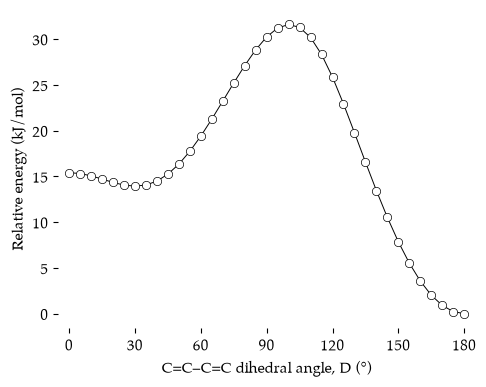

In [27]:
#| label: plot-butadiene-EvsD1
#| caption: Plot of relative energy (in kJ/mole) vs the frozebn dihedral angle for the `1 2 3 4` bond torsion

# get data from results list
Ds = [point["D"] for point in results]
Es = [point["E"] for point in results]  # in hartree units

E_min = min(Es)                             # relative energy
E_rel = [(E - E_min) * 2625.5 for E in Es]  # kJ/mol relative to the lowest point

fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(5,4)) # create an empty plot object

# plot data points
ax.plot(Ds, E_rel, color="black", linewidth=0.7, 
        marker="o", markerfacecolor="white",
        markeredgecolor="black", markeredgewidth=0.5, 
        zorder=1)

# style settings
ax.set_xlabel("C=C–C=C dihedral angle, D (°)")
ax.set_ylabel("Relative energy (kJ/mol)")
ax.set_xlim(-5, 185)
ax.set_xticks([0,30,60,90,120,150,180])
plt.show()

## The Results List

We collected the **results** in a list named `results`. It is a **list** of dictionaries, one dictionary for **each value** of `D`. In each dictionary is stored the **dihedral angle**, `D`, the **energy**, `E`, and several **other** outputs from each calculation, including a dictionary of values for the Z-matrix **variables**. We can extract other values and **plot** them without running the calculation again.

The structure of a **dictionary** in the results **list** is described below.

``` python
{
    "D",         # the set frozen dihedral for the 1234 bond torsion
    "E",         # energy (in Hartees) of optimized geometry 
    "steps",     # number of steps taken in optimization (large number indicate a troubles optimization)
    "E_homo",    # energy of HOMO (in eV)
    "E_lumo",    # energy of LUMO (in eV)
    "sym",       # symmetry used by Psi4 in the calculation
    "PG",        # true point group of the geometry
    "xyz",       # text block of cartessian coordinates for optimized geometry
    "Z",         # text block of Z-matrix, with variables for optimized geometry
    "var": {     # dictionary of variable values after optimization
            "rCCcent",     # bond distances
            "rCCterm",
            "rCHtermen",
            "rCHtermex",
            "rCHcent",
            "aCCC",        # bond angles
            "aHCCendo",
            "aHCHterm",
            "aHCCcent",
            "tHCCCendo",   # dihedral angles for bond torsions
            "tHCHC",
            "tHCCCcent",
            "D"            # value for the torsion that is being set and frozen
    }
}
```

## Save Your Work

If we used **higher** levels of theory, a **larger** molecule, or wanted **more** data points (or all three combined), we might have a scan that takes hours. rather than repeat that use of computer time, we can **write** the data in the `results` list to a text file and **read** it in again when we want to analyze the data in **new** ways.

The [code below](#save-to-json-butadiene1) **saves** the list of dictionaries in a **text** format called *json*. It is a **structured** file that can be inspected with a text editor. It can also be read in and **reconstructed** into the same `results` list at a later date.

In [28]:
#| label: save-to-json-butadiene1

# name = "butadiene_scan_HF_631.json"
name = "butadiene_scan_B3LYP-D3BJ_631GX.json"
# name = "butadiene_scan_HF_631-nosym.json"
# name = "butadiene_scan_B3LYP-D3BJ_631GX-nosym.json"

# Save the `results` object as json format so the scan doesn't have to be re-run
with open(data_dir / name, "w") as f:
    json.dump(results, f, indent=2)

print(f"saved json file to {name}")

saved json file to butadiene_scan_B3LYP-D3BJ_631GX.json


In the [next notebook](#json-to-plots-butadiene1), we will **explore** the data set in a number of ways. We will read in the *json* file rather than repeat the calculation.

If you want to **repeat** the above calculation with different **settings**, such as adding in the `symmetry C2` line or using **higher levels** of theory, you can rename the file name in the [code block above](#save-to-json-butadiene1) (start a scan with just two points to get a sense of the time before running the scan with 36 points as above.)

## Other Scans

I made **scans** for the **torsion** angle using the `HF/6-31G` and the `B3LYP-D3BJ/6-31G*` levels of theory. I also **repeated** those scans using a Z-matrix that had no requirements for **symmetery**. The [code below](#zmatrix-butadiene-simple-again) will build that Z-matrix. Will it affect the results?

To make this Z-matrix I just duplicated every variable that was doubled by symmetry and then gave each an "A" or "B" option. Now there are 24 variable names for the 24 internal coordinates. I could have just entered values for each parameter in the Z-matrix directly and kept only the `D` variable, like in the [previous notebook](simple_butadiene.ipynb#zmatrix-butadiene-simple). By using variables, I can query each parameter easily using `mol.get_variable()`.

I also tweaked some of the initial values to ensure that we are not in any kind of perfect $C_2$ symmetry.


In [18]:
#| label: zmatrix-butadiene-simple-again

# All paired-variables duplicated so that all variables are unique.
zmat = '''
0 1
C
C   1  rCCtermA
C   2  rCCcent      1  aCCCA
C   3  rCCtermB      2  aCCCB         1  D
H   1  rCHtermenA    2  aHCCendoA     3  tHCCCendoA
H   1  rCHtermexA    5  aHCHtermA     2  tHCHCA
H   2  rCHcentA      1  aHCCcentA     3  tHCCCcentA
H   3  rCHcentB      4  aHCCcentB     2  tHCCCcentB
H   4  rCHtermenB    3  aHCCendoB     2  tHCCCendoB
H   4  rCHtermexB    9  aHCHtermB     3  tHCHCB

rCCcent = 1.5
rCCtermA = 1.4
rCCtermB = 1.4
rCHtermenA = 1.1
rCHtermenB = 1.2
rCHtermexA = 1.1
rCHtermexB = 1.1
rCHcentA = 1.1
rCHcentB = 1.1
aCCCA = 120
aCCCB = 120
aHCCendoA = 120
aHCCendoB = 122
aHCHtermA = 120
aHCHtermB = 120
aHCCcentA = 120
aHCCcentB = 120
tHCCCendoA  =   1.0
tHCCCendoB  =   -1.0
tHCHCA  = 180.0
tHCHCB  = 180.0
tHCCCcentA = 180.0
tHCCCcentB = 180.0
D   = 180
symmetry C1
'''

mol = psi4.geometry(zmat)
